# K-Means Clustering - Part 1: Generate and Visualize Data

The main idea is to generate data, visualize it, and let K-Means discover groups **without using the existing labels**.

## 1. Generate a dataset

We use `make_blobs()` from Scikit-learn to generate 500 data points with two features.

In [7]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=5,
    random_state=42
)

### What do these parameters mean?

| Parameter | Meaning |
|---|---|
| `n_samples=500` | Generate 500 data points |
| `n_features=2` | Each point has two features |
| `centers=5` | Generate data around five centers |
| `random_state=42` | Make the generated dataset reproducible |

The resulting shapes are:

In [3]:
print(X.shape)  # (500, 2)
print(y.shape)  # (500,)

(500, 2)
(500,)


- `X` contains the feature values.
- `y` contains the original group labels generated by `make_blobs()`.

## 2. Why don't we use `y`?

K-Means is an **unsupervised** learning algorithm, so it discovers clusters from `X` without needing the correct labels.

In this lecture, `y` is kept only so you can compare the discovered clusters with the original groups later.

> Think of it like receiving 500 customer records without knowing which customer group each person belongs to. K-Means tries to discover those groups on its own.

## 3. Visualize the data

Because each point has only two features, we can plot it on a 2D graph.

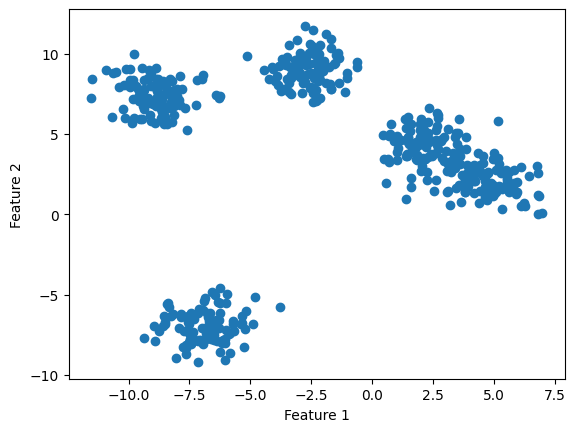

In [8]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Here:

- `X[:, 0]` selects all rows from the first column (Feature 1), plotted on the x-axis.
- `X[:, 1]` selects all rows from the second column (Feature 2), plotted on the y-axis.

# K-Means Implementation - Part 2: Initializing Centroids

In this lecture, we implement the first step of K-Means: **randomly initializing the centroids**.

Let's understand it using the pizza-shop example.

## 1. Real-life example: Where should we open pizza shops?

Imagine 500 customers live in different locations across a city. You want to open 3 pizza shops so that customers are, on average, close to a shop.

- Each **customer** is a data point with coordinates $(x, y)$.
- Each **pizza shop** is a centroid.
- $K = 3$ means we want 3 clusters and 3 shop locations.

K-Means tries to place the shops to **minimize the total squared distance** between each customer and their nearest shop.

## 2. Normalize the dataset

The lecture first standardizes the features:

$$
x' = \frac{x - \mu}{\sigma}
$$

Where:

- $x$ = original feature value.
- $\mu$ = mean of that feature.
- $\sigma$ = standard deviation.
- $x'$ = standardized value.

This gives the features a comparable scale, which is important when distances are used.

In [9]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=5,
    random_state=42
)

scaler = StandardScaler()
X = scaler.fit_transform(X)

Here, `y` is not used by K-Means; it is available only for comparison with the original generated groups.

## 3. Randomly initialize K centroids

The lecture chooses $K = 5$ and generates random coordinates for each centroid.

In [10]:
import numpy as np

K = 5
num_features = X.shape[1]

for i in range(K):
    center = 2 * np.random.random(num_features) - 1
    center = center * K
    print(center)

[2.55159128 0.39405956]
[0.52480298 4.97260004]
[ 2.71009818 -2.00603083]
[ 4.48661872 -0.30145659]
[ 3.26033411 -1.19702716]


### Breaking down the random initialization formula

```python
np.random.random(num_features)
```

Generates random numbers between 0 and 1. Since there are two features, it generates two coordinates.

```python
2 * np.random.random(num_features) - 1
```

Transforms the numbers to the range $[-1, 1)$.

```python
center = center * K
```

Scales them to approximately $[-K, K)$.

For example, if $K = 5$, the generated coordinates fall approximately between $-5$ and $5$.

The purpose is to initialize the centroids within a reasonable region rather than far away from the data.

> **Note:** The lecture's initialization range is a teaching choice. In production implementations, K-Means commonly initializes centroids using data points or the **K-Means++** method.

## 4. Store each centroid in a dictionary

The lecture stores three things about every centroid:

- `center`: its coordinates.
- `color`: its display color.
- `points`: the data points assigned to it.

In [12]:
colors = ["green", "red", "blue", "yellow", "orange"]

centroids = {}

for i in range(K):
    center = 2 * np.random.random(num_features) - 1
    center = center * K

    centroids[i] = {
        "center": center,
        "color": colors[i],
        "points": []
    }

The dictionary will have a structure like this:

```python
{
    0: {
        "center": [1.2, -2.3],
        "color": "green",
        "points": []
    },
    1: {
        "center": [-3.1, 0.8],
        "color": "red",
        "points": []
    }
}
```

These coordinates and colors are just examples; your actual coordinates will be randomly generated.

The `points` list is initially empty because the algorithm has not assigned any data points yet.